# 03 — Davis Model Comparison

This notebook compares three drug graph models:

- GCN + CNN
- GAT + CNN
- GIN + CNN

To ensure a fair comparison, all models use:

- the same Davis train, validation and test sets;
- the same protein CNN;
- the same batch size;
- the same learning rate;
- the same random seed;
- the same evaluation metrics.

# Imports and project setup

In [2]:
from pathlib import Path
import sys

import pandas as pd
import torch
from IPython.display import display
from torch_geometric.loader import DataLoader

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    RANDOM_SEED,
    BATCH_SIZE,
    NUM_WORKERS,
    LEARNING_RATE,
    WEIGHT_DECAY,
    NUM_EPOCHS,
    EARLY_STOPPING_PATIENCE,
    PROCESSED_DATA_DIR,
    SPLITS_DIR,
    MODELS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    PLOTS_DIR,
)

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

from src.splits import validate_split_integrity

from src.models import create_dta_model

from src.training import (
    fit_model,
    evaluate_model,
    predict,
    append_experiment_log,
)

from src.utils import (
    set_random_seed,
    get_device,
    count_trainable_parameters,
    save_json,
    load_json,
)

set_random_seed(RANDOM_SEED)

device = get_device()

print("Device:", device)
print("Project root:", PROJECT_ROOT)

Device: mps
Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing


# Load the complete Davis dataset

In [3]:
davis_df = pd.read_csv(
    PROCESSED_DATA_DIR / "davis_pairs.csv"
)

print("Complete Davis dataset:", davis_df.shape)
print("Unique drugs:", davis_df["drug_id"].nunique())
print("Unique targets:", davis_df["target_id"].nunique())

Complete Davis dataset: (30056, 8)
Unique drugs: 68
Unique targets: 442


# Load the same saved random split

In [4]:
random_split_directory = SPLITS_DIR / "random"

train_df = pd.read_csv(
    random_split_directory / "davis_train.csv"
)

validation_df = pd.read_csv(
    random_split_directory / "davis_validation.csv"
)

test_df = pd.read_csv(
    random_split_directory / "davis_test.csv"
)

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

Training rows: 21039
Validation rows: 4508
Test rows: 4509


# Confirm the split is correct

In [5]:
split_report = validate_split_integrity(
    train_dataframe=train_df,
    validation_dataframe=validation_df,
    test_dataframe=test_df,
    split_type="random",
)

display(pd.DataFrame([split_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,21039,4508,4509,False,True,True


# Create reusable drug and protein features

In [6]:
drug_graph_cache = build_drug_graph_cache(
    davis_df
)

protein_tensor_cache = build_protein_tensor_cache(
    davis_df
)

print("Drug graphs:", len(drug_graph_cache))
print("Protein tensors:", len(protein_tensor_cache))

Drug graphs: 68
Protein tensors: 442


# Create the datasets

In [7]:
train_dataset = DTADataset(
    dataframe=train_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

validation_dataset = DTADataset(
    dataframe=validation_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

test_dataset = DTADataset(
    dataframe=test_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))

Training samples: 21039
Validation samples: 4508
Test samples: 4509


# Create the DataLoaders

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Batch size: 32
Training batches: 658
Validation batches: 141
Test batches: 141


# Check one batch

In [9]:
batch = next(iter(train_loader))

print("Graphs in batch:", batch.num_graphs)
print("Drug node features:", batch.x.shape)
print("Protein batch:", batch.target.shape)
print("Affinity batch:", batch.y.shape)

assert batch.target.shape[1] == 1000
assert batch.x.shape[1] == 6
assert batch.y.shape[0] == batch.num_graphs

print("Model-comparison data are ready.")

Graphs in batch: 32
Drug node features: torch.Size([1026, 6])
Protein batch: torch.Size([32, 1000])
Affinity batch: torch.Size([32])
Model-comparison data are ready.


## GAT + CNN Model

This experiment replaces the GCN drug encoder with a Graph Attention Network.

The protein encoder, dataset split and training settings remain unchanged.

# Reset the random seed

In [10]:
set_random_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


# Create the GAT + CNN model

In [11]:
gat_model = create_dta_model(
    model_name="gat"
)

gat_model = gat_model.to(device)

print("GAT + CNN model created.")
print("Device:", device)
print(
    "Trainable parameters:",
    f"{count_trainable_parameters(gat_model):,}"
)

GAT + CNN model created.
Device: mps
Trainable parameters: 300,033


# Test one forward pass

In [12]:
example_batch = next(iter(train_loader))
example_batch = example_batch.to(device)

gat_model.eval()

with torch.no_grad():
    example_predictions = gat_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True affinity shape:", example_batch.y.shape)

assert example_predictions.shape[0] == example_batch.num_graphs
assert torch.isfinite(example_predictions).all()

print("GAT + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True affinity shape: torch.Size([32])
GAT + CNN forward pass successful.


# Create the optimiser

In [13]:
gat_optimizer = torch.optim.Adam(
    gat_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early stopping patience: 7


# Set the model path

In [14]:
gat_checkpoint_path = (
    MODELS_DIR
    / "best_davis_gat_cnn.pt"
)

print("GAT model will be saved to:")
print(gat_checkpoint_path)

GAT model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gat_cnn.pt


# Train GAT + CNN

In [15]:
gat_training_result = fit_model(
    model=gat_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    optimizer=gat_optimizer,
    device=device,
    checkpoint_path=gat_checkpoint_path,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gat",
        "protein_encoder": "cnn",
        "split_type": "random",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1350 | Validation MSE: 0.9255 | RMSE: 0.9621 | MAE: 0.8419
Epoch 002 | Train MSE: 0.9268 | Validation MSE: 0.6656 | RMSE: 0.8158 | MAE: 0.5632
Epoch 003 | Train MSE: 0.8886 | Validation MSE: 0.6769 | RMSE: 0.8228 | MAE: 0.4973
Epoch 004 | Train MSE: 0.8655 | Validation MSE: 0.6296 | RMSE: 0.7934 | MAE: 0.5386
Epoch 005 | Train MSE: 0.8416 | Validation MSE: 0.6145 | RMSE: 0.7839 | MAE: 0.4865
Epoch 006 | Train MSE: 0.8235 | Validation MSE: 0.6091 | RMSE: 0.7804 | MAE: 0.5685
Epoch 007 | Train MSE: 0.8126 | Validation MSE: 0.6060 | RMSE: 0.7785 | MAE: 0.4634
Epoch 008 | Train MSE: 0.7862 | Validation MSE: 0.6222 | RMSE: 0.7888 | MAE: 0.6050
Epoch 009 | Train MSE: 0.7764 | Validation MSE: 0.6007 | RMSE: 0.7750 | MAE: 0.5626
Epoch 010 | Train MSE: 0.7773 | Validation MSE: 0.5917 | RMSE: 0.7692 | MAE: 0.5639
Epoch 011 | Train MSE: 0.7585 | Validation MSE: 0.5700 | RMSE: 0.7550 | MAE: 0.5006
Epoch 012 | Train MSE: 0.7522 | Validation MSE: 0.6267 | RMSE: 0.7916 | MAE:

# Check the best validation result

In [16]:
gat_model = gat_training_result["model"]

print("Best epoch:", gat_training_result["best_epoch"])

print("\nBest validation metrics:")

for metric_name, metric_value in (
    gat_training_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 29

Best validation metrics:
mse: 0.4851
rmse: 0.6965
mae: 0.4899
concordance_index: 0.7984
pearson_correlation: 0.6253


# Save the training history

In [17]:
gat_history_df = pd.DataFrame(
    gat_training_result["history"]
)

gat_history_path = (
    METRICS_DIR
    / "davis_gat_cnn_training_history.csv"
)

gat_history_df.to_csv(
    gat_history_path,
    index=False,
)

print("Training history saved to:")
print(gat_history_path)

display(gat_history_df.tail())

Training history saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_training_history.csv


,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.640373,0.507675,0.712513,0.476756,0.776106,0.594010
26,27,0.633366,0.498414,0.705984,0.490890,0.797414,0.613134
27,28,0.629540,0.495763,0.704104,0.425644,0.800231,0.611547
28,29,0.609925,0.485106,0.696496,0.489924,0.798373,0.625338
29,30,0.605674,0.486482,0.697483,0.439214,0.801282,0.613912


# Evaluate GAT on the test set

In [18]:
gat_test_metrics = evaluate_model(
    model=gat_model,
    data_loader=test_loader,
    device=device,
)

print("Davis GAT + CNN test results")

for metric_name, metric_value in gat_test_metrics.items():
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Davis GAT + CNN test results
mse: 0.5100
rmse: 0.7141
mae: 0.4988
concordance_index: 0.7963
pearson_correlation: 0.6060


# Save the test metrics

In [19]:
gat_test_metrics_path = (
    METRICS_DIR
    / "davis_gat_cnn_test_metrics.json"
)

save_json(
    data=gat_test_metrics,
    output_path=gat_test_metrics_path,
)

print("Test metrics saved to:")
print(gat_test_metrics_path)

Test metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_test_metrics.json


# Generate and save test predictions

In [20]:
gat_true_values, gat_predicted_values, _ = predict(
    model=gat_model,
    data_loader=test_loader,
    device=device,
)

gat_predictions_df = test_df.reset_index(
    drop=True
).copy()

assert len(gat_predictions_df) == len(gat_true_values)
assert len(gat_predictions_df) == len(gat_predicted_values)

gat_predictions_df["true_affinity"] = gat_true_values
gat_predictions_df["predicted_affinity"] = gat_predicted_values

gat_predictions_df["absolute_error"] = (
    gat_predictions_df["true_affinity"]
    - gat_predictions_df["predicted_affinity"]
).abs()

gat_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gat_cnn_test_predictions.csv"
)

gat_predictions_df.to_csv(
    gat_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(gat_predictions_path)

display(gat_predictions_df.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gat_cnn_test_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,16722836,FLT3(ITD),CC1=CN=C(N=C1NC2=CC(=CC=C2)S(=O)(=O)NC(C)(C)C)...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,16.0,7.795880,pKd,7.795880,7.031587,0.764293
1,davis,11984591,RET,CC1(C(=O)NC2=C(O1)C=CC(=N2)NC3=NC(=NC=C3F)NC4=...,MAKATSGAAGLRLLLLLLLPLLGKVALGLYFSRDAYWEKLYVDQAA...,4.1,8.387216,pKd,8.387217,7.262630,1.124587
2,davis,6918454,SNRK,C1CC1CONC(=O)C2=C(C(=C(C=C2)F)F)NC3=C(C=C(C=C3...,MAGFKRGYDGKIAGLYDLDKTLGRGHFAVVKLARHVFTGEKVAVKV...,10000.0,5.000000,pKd,5.000000,5.024913,0.024913
3,davis,44150621,TSSK1B,CC(C(=O)O)O.CN1CCN(CC1)C2=CC3=C(C=C2)NC(=C4C(=...,MDDAAVLKRRGYLLGINLGEGSYAKVKSAYSERLKFNVAIKIIDRK...,10000.0,5.000000,pKd,5.000000,5.208660,0.208660
4,davis,11717001,STK35,C1CC(=NO)C2=C1C=C(C=C2)C3=CN(N=C3C4=CC=NC=C4)CCO,MGHQESPLARAPAGGAAYVKRLCKGLSWREHVESHGSLGAQASPAS...,10000.0,5.000000,pKd,5.000000,5.338758,0.338758


# Plot the training history

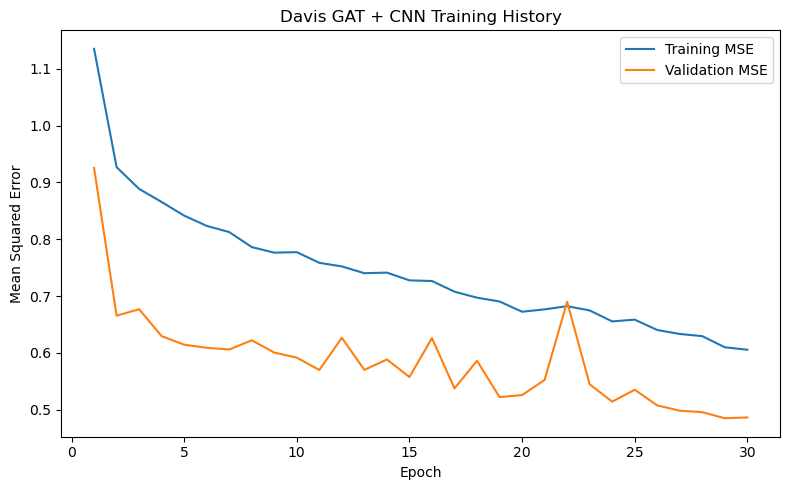

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    gat_history_df["epoch"],
    gat_history_df["train_mse"],
    label="Training MSE",
)

plt.plot(
    gat_history_df["epoch"],
    gat_history_df["validation_mse"],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GAT + CNN Training History")
plt.legend()
plt.tight_layout()

gat_training_plot_path = (
    PLOTS_DIR
    / "davis_gat_cnn_training_history.png"
)

plt.savefig(
    gat_training_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Plot true versus predicted values

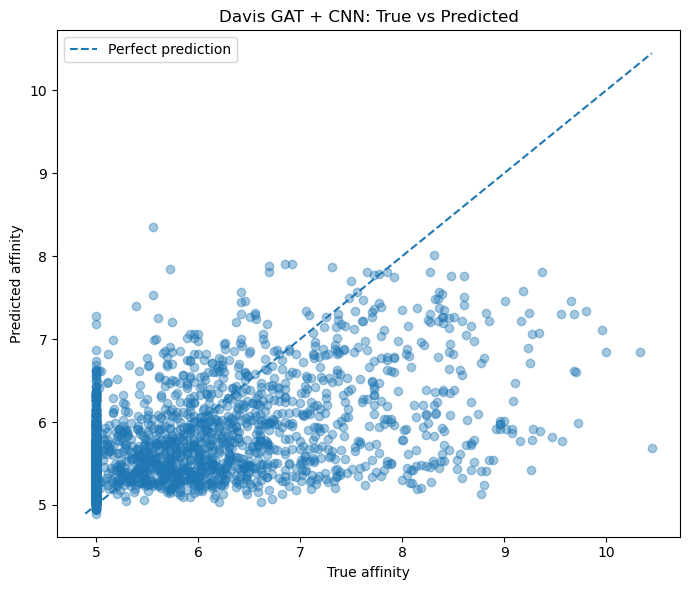

In [22]:
plt.figure(figsize=(7, 6))

plt.scatter(
    gat_true_values,
    gat_predicted_values,
    alpha=0.4,
)

minimum_value = min(
    gat_true_values.min(),
    gat_predicted_values.min(),
)

maximum_value = max(
    gat_true_values.max(),
    gat_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction",
)

plt.xlabel("True affinity")
plt.ylabel("Predicted affinity")
plt.title("Davis GAT + CNN: True vs Predicted")
plt.legend()
plt.tight_layout()

gat_prediction_plot_path = (
    PLOTS_DIR
    / "davis_gat_cnn_true_vs_predicted.png"
)

plt.savefig(
    gat_prediction_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Add GAT to the experiment log

In [23]:
append_experiment_log(
    dataset="davis",
    model_name="gat",
    protein_encoder="cnn",
    split_type="random",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(gat_history_df),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=gat_training_result[
        "best_validation_metrics"
    ]["mse"],
    test_metrics=gat_test_metrics,
    model_path=gat_checkpoint_path,
    model=gat_model,
)

print("GAT experiment added to experiment_log.csv")

GAT experiment added to experiment_log.csv


# Confirm the outputs

In [24]:
gat_output_files = [
    gat_checkpoint_path,
    gat_history_path,
    gat_test_metrics_path,
    gat_predictions_path,
    gat_training_plot_path,
    gat_prediction_plot_path,
]

for file_path in gat_output_files:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in gat_output_files
)

print("GAT + CNN experiment completed successfully.")

best_davis_gat_cnn.pt → True
davis_gat_cnn_training_history.csv → True
davis_gat_cnn_test_metrics.json → True
davis_gat_cnn_test_predictions.csv → True
davis_gat_cnn_training_history.png → True
davis_gat_cnn_true_vs_predicted.png → True
GAT + CNN experiment completed successfully.


## GIN + CNN Model

This experiment replaces the drug graph encoder with a Graph Isomorphism Network.

The protein encoder, dataset split and training settings remain unchanged.

# Reset the random seed

In [26]:
set_random_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


# Create the GIN + CNN model

In [27]:
gin_model = create_dta_model(
    model_name="gin"
)

gin_model = gin_model.to(device)

print("GIN + CNN model created.")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(gin_model):,}"
)

GIN + CNN model created.
Device: mps
Trainable parameters: 348,801


# Test one forward pass

In [28]:
example_batch = next(iter(train_loader))
example_batch = example_batch.to(device)

gin_model.eval()

with torch.no_grad():
    example_predictions = gin_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True affinity shape:", example_batch.y.shape)

assert example_predictions.shape[0] == example_batch.num_graphs
assert torch.isfinite(example_predictions).all()

print("GIN + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True affinity shape: torch.Size([32])
GIN + CNN forward pass successful.


# Create the optimiser

In [29]:
gin_optimizer = torch.optim.Adam(
    gin_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early stopping patience: 7


# Set the model path

In [30]:
gin_checkpoint_path = (
    MODELS_DIR
    / "best_davis_gin_cnn.pt"
)

print("GIN model will be saved to:")
print(gin_checkpoint_path)

GIN model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gin_cnn.pt


# Train GIN + CNN

In [31]:
gin_training_result = fit_model(
    model=gin_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    optimizer=gin_optimizer,
    device=device,
    checkpoint_path=gin_checkpoint_path,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gin",
        "protein_encoder": "cnn",
        "split_type": "random",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1343 | Validation MSE: 1.3125 | RMSE: 1.1456 | MAE: 0.8205
Epoch 002 | Train MSE: 0.9395 | Validation MSE: 0.6583 | RMSE: 0.8114 | MAE: 0.5873
Epoch 003 | Train MSE: 0.9230 | Validation MSE: 0.7220 | RMSE: 0.8497 | MAE: 0.6717
Epoch 004 | Train MSE: 0.9102 | Validation MSE: 0.6285 | RMSE: 0.7928 | MAE: 0.5025
Epoch 005 | Train MSE: 0.8826 | Validation MSE: 0.6788 | RMSE: 0.8239 | MAE: 0.5104
Epoch 006 | Train MSE: 0.8637 | Validation MSE: 0.8321 | RMSE: 0.9122 | MAE: 0.5798
Epoch 007 | Train MSE: 0.8622 | Validation MSE: 1.0241 | RMSE: 1.0120 | MAE: 0.7218
Epoch 008 | Train MSE: 0.8464 | Validation MSE: 0.6256 | RMSE: 0.7909 | MAE: 0.4995
Epoch 009 | Train MSE: 0.8535 | Validation MSE: 0.6996 | RMSE: 0.8364 | MAE: 0.5030
Epoch 010 | Train MSE: 0.8263 | Validation MSE: 0.6503 | RMSE: 0.8064 | MAE: 0.5914
Epoch 011 | Train MSE: 0.8048 | Validation MSE: 0.7171 | RMSE: 0.8468 | MAE: 0.5260
Epoch 012 | Train MSE: 0.8034 | Validation MSE: 0.5923 | RMSE: 0.7696 | MAE:

# Check the best validation result

In [32]:
gin_model = gin_training_result["model"]

print("Best epoch:", gin_training_result["best_epoch"])

print("\nBest validation metrics:")

for metric_name, metric_value in (
    gin_training_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 14

Best validation metrics:
mse: 0.5569
rmse: 0.7463
mae: 0.4982
concordance_index: 0.7560
pearson_correlation: 0.5308


# Save the training history

In [33]:
gin_history_df = pd.DataFrame(
    gin_training_result["history"]
)

gin_history_path = (
    METRICS_DIR
    / "davis_gin_cnn_training_history.csv"
)

gin_history_df.to_csv(
    gin_history_path,
    index=False,
)

print("Training history saved to:")
print(gin_history_path)

display(gin_history_df.tail())

Training history saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_training_history.csv


,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
16,17,0.729100,0.664488,0.815161,0.512000,0.775660,0.541119
17,18,0.737835,0.622836,0.789199,0.487307,0.756808,0.522156
18,19,0.714513,0.556805,0.746194,0.478139,0.786338,0.568280
19,20,0.695616,0.567615,0.753403,0.473470,0.788098,0.565087
20,21,0.687050,0.586155,0.765607,0.476093,0.779300,0.547245


# Evaluate GIN on the test set

In [34]:
gin_test_metrics = evaluate_model(
    model=gin_model,
    data_loader=test_loader,
    device=device,
)

print("Davis GIN + CNN test results")

for metric_name, metric_value in gin_test_metrics.items():
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Davis GIN + CNN test results
mse: 0.5999
rmse: 0.7745
mae: 0.5101
concordance_index: 0.7494
pearson_correlation: 0.4902


# Save the test metrics

In [35]:
gin_test_metrics_path = (
    METRICS_DIR
    / "davis_gin_cnn_test_metrics.json"
)

save_json(
    data=gin_test_metrics,
    output_path=gin_test_metrics_path,
)

print("Test metrics saved to:")
print(gin_test_metrics_path)

Test metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_test_metrics.json


# Generate and save predictions

In [36]:
gin_true_values, gin_predicted_values, _ = predict(
    model=gin_model,
    data_loader=test_loader,
    device=device,
)

gin_predictions_df = test_df.reset_index(
    drop=True
).copy()

assert len(gin_predictions_df) == len(gin_true_values)
assert len(gin_predictions_df) == len(gin_predicted_values)

gin_predictions_df["true_affinity"] = gin_true_values
gin_predictions_df["predicted_affinity"] = gin_predicted_values

gin_predictions_df["absolute_error"] = (
    gin_predictions_df["true_affinity"]
    - gin_predictions_df["predicted_affinity"]
).abs()

gin_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gin_cnn_test_predictions.csv"
)

gin_predictions_df.to_csv(
    gin_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(gin_predictions_path)

display(gin_predictions_df.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gin_cnn_test_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,16722836,FLT3(ITD),CC1=CN=C(N=C1NC2=CC(=CC=C2)S(=O)(=O)NC(C)(C)C)...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,16.0,7.795880,pKd,7.795880,6.602474,1.193406
1,davis,11984591,RET,CC1(C(=O)NC2=C(O1)C=CC(=N2)NC3=NC(=NC=C3F)NC4=...,MAKATSGAAGLRLLLLLLLPLLGKVALGLYFSRDAYWEKLYVDQAA...,4.1,8.387216,pKd,8.387217,6.353881,2.033336
2,davis,6918454,SNRK,C1CC1CONC(=O)C2=C(C(=C(C=C2)F)F)NC3=C(C=C(C=C3...,MAGFKRGYDGKIAGLYDLDKTLGRGHFAVVKLARHVFTGEKVAVKV...,10000.0,5.000000,pKd,5.000000,4.850607,0.149393
3,davis,44150621,TSSK1B,CC(C(=O)O)O.CN1CCN(CC1)C2=CC3=C(C=C2)NC(=C4C(=...,MDDAAVLKRRGYLLGINLGEGSYAKVKSAYSERLKFNVAIKIIDRK...,10000.0,5.000000,pKd,5.000000,5.350266,0.350266
4,davis,11717001,STK35,C1CC(=NO)C2=C1C=C(C=C2)C3=CN(N=C3C4=CC=NC=C4)CCO,MGHQESPLARAPAGGAAYVKRLCKGLSWREHVESHGSLGAQASPAS...,10000.0,5.000000,pKd,5.000000,5.091086,0.091086


# Plot the training history

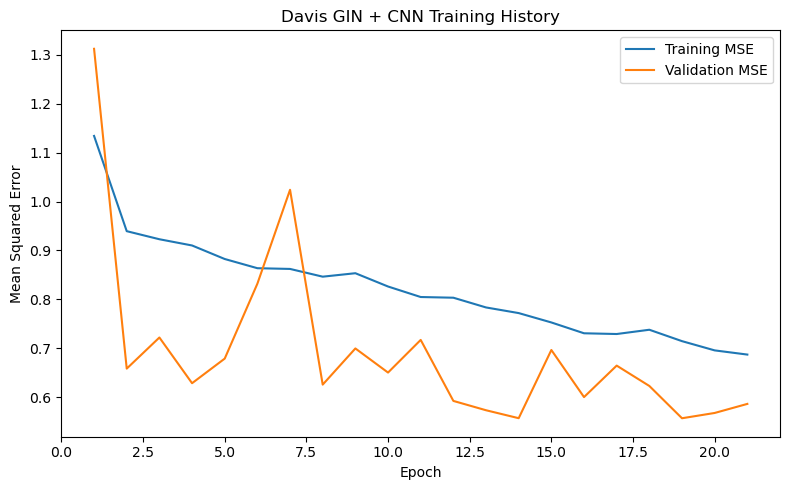

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gin_cnn_training_history.png


In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    gin_history_df["epoch"],
    gin_history_df["train_mse"],
    label="Training MSE",
)

plt.plot(
    gin_history_df["epoch"],
    gin_history_df["validation_mse"],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GIN + CNN Training History")
plt.legend()
plt.tight_layout()

gin_training_plot_path = (
    PLOTS_DIR
    / "davis_gin_cnn_training_history.png"
)

plt.savefig(
    gin_training_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(gin_training_plot_path)

# Plot true versus predicted affinity

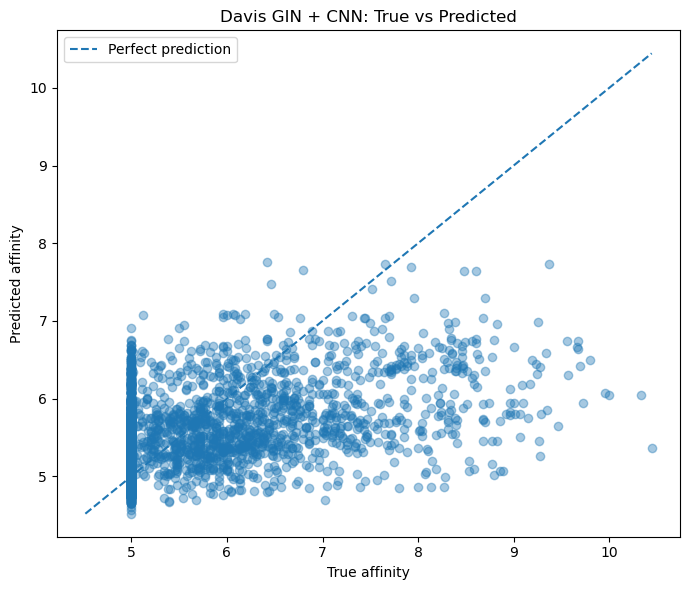

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gin_cnn_true_vs_predicted.png


In [38]:
plt.figure(figsize=(7, 6))

plt.scatter(
    gin_true_values,
    gin_predicted_values,
    alpha=0.4,
)

minimum_value = min(
    gin_true_values.min(),
    gin_predicted_values.min(),
)

maximum_value = max(
    gin_true_values.max(),
    gin_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction",
)

plt.xlabel("True affinity")
plt.ylabel("Predicted affinity")
plt.title("Davis GIN + CNN: True vs Predicted")
plt.legend()
plt.tight_layout()

gin_prediction_plot_path = (
    PLOTS_DIR
    / "davis_gin_cnn_true_vs_predicted.png"
)

plt.savefig(
    gin_prediction_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(gin_prediction_plot_path)

# Add GIN to the experiment log

In [39]:
append_experiment_log(
    dataset="davis",
    model_name="gin",
    protein_encoder="cnn",
    split_type="random",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(gin_history_df),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=gin_training_result[
        "best_validation_metrics"
    ]["mse"],
    test_metrics=gin_test_metrics,
    model_path=gin_checkpoint_path,
    model=gin_model,
)

print("GIN experiment added to experiment_log.csv")

GIN experiment added to experiment_log.csv


# Confirm all GIN outputs

In [40]:
gin_output_files = [
    gin_checkpoint_path,
    gin_history_path,
    gin_test_metrics_path,
    gin_predictions_path,
    gin_training_plot_path,
    gin_prediction_plot_path,
]

for file_path in gin_output_files:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in gin_output_files
)

print("GIN + CNN experiment completed successfully.")

best_davis_gin_cnn.pt → True
davis_gin_cnn_training_history.csv → True
davis_gin_cnn_test_metrics.json → True
davis_gin_cnn_test_predictions.csv → True
davis_gin_cnn_training_history.png → True
davis_gin_cnn_true_vs_predicted.png → True
GIN + CNN experiment completed successfully.


## Compare GCN, GAT and GIN

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All models used the same Davis split, protein CNN, random seed and training settings.

Lower MSE, RMSE and MAE values are better.

Higher concordance index and Pearson correlation values are better.

# Load the saved test metrics

In [41]:
gcn_metrics = load_json(
    METRICS_DIR / "davis_gcn_cnn_test_metrics.json"
)

gat_metrics = load_json(
    METRICS_DIR / "davis_gat_cnn_test_metrics.json"
)

gin_metrics = load_json(
    METRICS_DIR / "davis_gin_cnn_test_metrics.json"
)

print("Saved test metrics loaded successfully.")

Saved test metrics loaded successfully.


# Load the training histories

In [42]:
gcn_history = pd.read_csv(
    METRICS_DIR / "davis_gcn_cnn_training_history.csv"
)

gat_history = pd.read_csv(
    METRICS_DIR / "davis_gat_cnn_training_history.csv"
)

gin_history = pd.read_csv(
    METRICS_DIR / "davis_gin_cnn_training_history.csv"
)

print("Training histories loaded successfully.")

Training histories loaded successfully.


# Calculate the parameter counts

In [43]:
gcn_parameter_count = count_trainable_parameters(
    create_dta_model("gcn")
)

gat_parameter_count = count_trainable_parameters(
    create_dta_model("gat")
)

gin_parameter_count = count_trainable_parameters(
    create_dta_model("gin")
)

print("GCN parameters:", f"{gcn_parameter_count:,}")
print("GAT parameters:", f"{gat_parameter_count:,}")
print("GIN parameters:", f"{gin_parameter_count:,}")

GCN parameters: 299,265
GAT parameters: 300,033
GIN parameters: 348,801


# Create the comparison table

In [44]:
comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "best_validation_mse": gcn_history[
                "validation_mse"
            ].min(),
            "test_mse": gcn_metrics["mse"],
            "test_rmse": gcn_metrics["rmse"],
            "test_mae": gcn_metrics["mae"],
            "concordance_index": gcn_metrics[
                "concordance_index"
            ],
            "pearson_correlation": gcn_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": gcn_parameter_count,
        },
        {
            "model": "GAT + CNN",
            "best_validation_mse": gat_history[
                "validation_mse"
            ].min(),
            "test_mse": gat_metrics["mse"],
            "test_rmse": gat_metrics["rmse"],
            "test_mae": gat_metrics["mae"],
            "concordance_index": gat_metrics[
                "concordance_index"
            ],
            "pearson_correlation": gat_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": gat_parameter_count,
        },
        {
            "model": "GIN + CNN",
            "best_validation_mse": gin_history[
                "validation_mse"
            ].min(),
            "test_mse": gin_metrics["mse"],
            "test_rmse": gin_metrics["rmse"],
            "test_mae": gin_metrics["mae"],
            "concordance_index": gin_metrics[
                "concordance_index"
            ],
            "pearson_correlation": gin_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": gin_parameter_count,
        },
    ]
)

comparison_df = comparison_df.sort_values(
    "best_validation_mse"
).reset_index(drop=True)

comparison_df.insert(
    0,
    "validation_rank",
    range(1, len(comparison_df) + 1),
)

display(
    comparison_df.round(4)
)

,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,1,GAT + CNN,0.4851,0.5100,0.7141,0.4988,0.7963,0.6060,300033
1,2,GIN + CNN,0.5568,0.5999,0.7745,0.5101,0.7494,0.4902,348801
2,3,GCN + CNN,0.5633,0.6067,0.7789,0.5024,0.7562,0.4829,299265


# Select the preliminary winner

In [45]:
preliminary_best_model = comparison_df.iloc[0]

print("Preliminary Davis random-split winner")
print("----------------------------------------")
print("Model:", preliminary_best_model["model"])
print(
    "Best validation MSE:",
    round(
        preliminary_best_model["best_validation_mse"],
        4,
    ),
)
print(
    "Test RMSE:",
    round(
        preliminary_best_model["test_rmse"],
        4,
    ),
)
print(
    "Test MAE:",
    round(
        preliminary_best_model["test_mae"],
        4,
    ),
)

Preliminary Davis random-split winner
----------------------------------------
Model: GAT + CNN
Best validation MSE: 0.4851
Test RMSE: 0.7141
Test MAE: 0.4988


# Save the comparison table

In [46]:
comparison_path = (
    METRICS_DIR
    / "davis_random_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False,
)

print("Comparison table saved to:")
print(comparison_path)

Comparison table saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_random_model_comparison.csv


# Plot test RMSE comparison

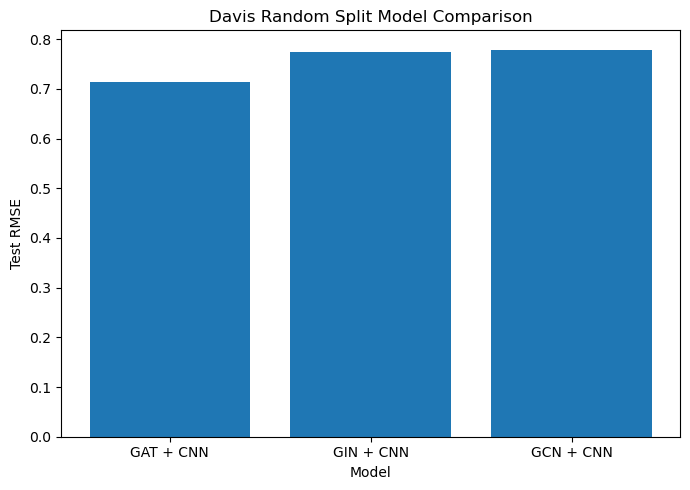

RMSE comparison plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_random_model_rmse_comparison.png


In [47]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["model"],
    comparison_df["test_rmse"],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")
plt.title("Davis Random Split Model Comparison")
plt.tight_layout()

rmse_plot_path = (
    PLOTS_DIR
    / "davis_random_model_rmse_comparison.png"
)

plt.savefig(
    rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("RMSE comparison plot saved to:")
print(rmse_plot_path)

# Plot concordance-index comparison

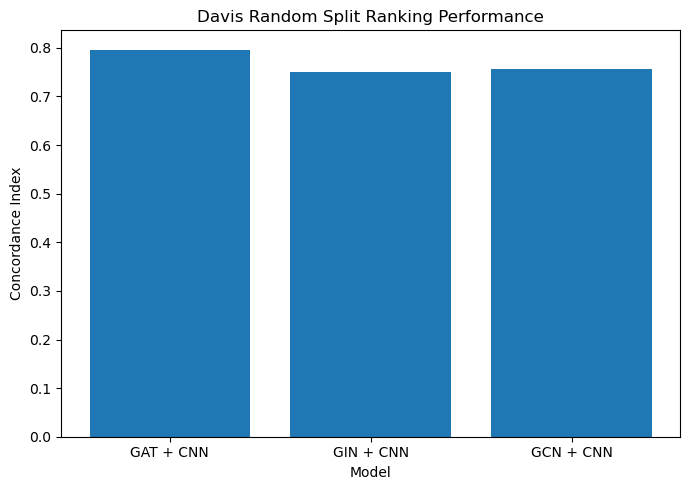

Concordance-index plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_random_model_ci_comparison.png


In [48]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["model"],
    comparison_df["concordance_index"],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")
plt.title("Davis Random Split Ranking Performance")
plt.tight_layout()

ci_plot_path = (
    PLOTS_DIR
    / "davis_random_model_ci_comparison.png"
)

plt.savefig(
    ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Concordance-index plot saved to:")
print(ci_plot_path)

# Confirm the saved outputs

In [49]:
comparison_outputs = [
    comparison_path,
    rmse_plot_path,
    ci_plot_path,
]

for output_path in comparison_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in comparison_outputs
)

print("Davis model comparison completed successfully.")

davis_random_model_comparison.csv → True
davis_random_model_rmse_comparison.png → True
davis_random_model_ci_comparison.png → True
Davis model comparison completed successfully.


# Davis Model Comparison Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and evaluated using the same Davis random split.

A preliminary winner was identified using validation MSE.

This is not yet the final model because the architectures must next be evaluated using:

- cold-drug splitting;
- cold-target splitting;
- the KIBA dataset;
- optional ESM-2 protein features.